In [1]:
## java runtime is no more available in colab. We'll have to install it manually.
!apt-get install openjdk-17-jdk-headless -qq > /dev/null

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pyspark.sql import SparkSession
spark=SparkSession.builder.appName('bank_data').getOrCreate()

In [4]:
df=spark.read.csv('bank.csv',header=True,inferSchema=True)
df.printSchema()

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- deposit: string (nullable = true)



In [5]:
df.show()

+---+-----------+--------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+
|age|        job| marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|deposit|
+---+-----------+--------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+
| 59|     admin.| married|secondary|     no|   2343|    yes|  no|unknown|  5|  may|    1042|       1|   -1|       0| unknown|    yes|
| 56|     admin.| married|secondary|     no|     45|     no|  no|unknown|  5|  may|    1467|       1|   -1|       0| unknown|    yes|
| 41| technician| married|secondary|     no|   1270|    yes|  no|unknown|  5|  may|    1389|       1|   -1|       0| unknown|    yes|
| 55|   services| married|secondary|     no|   2476|    yes|  no|unknown|  5|  may|     579|       1|   -1|       0| unknown|    yes|
| 54|     admin.| married| tertiary|     no|    184|     no|  

In [6]:
df.show(5)

+---+----------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+
|age|       job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|deposit|
+---+----------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+
| 59|    admin.|married|secondary|     no|   2343|    yes|  no|unknown|  5|  may|    1042|       1|   -1|       0| unknown|    yes|
| 56|    admin.|married|secondary|     no|     45|     no|  no|unknown|  5|  may|    1467|       1|   -1|       0| unknown|    yes|
| 41|technician|married|secondary|     no|   1270|    yes|  no|unknown|  5|  may|    1389|       1|   -1|       0| unknown|    yes|
| 55|  services|married|secondary|     no|   2476|    yes|  no|unknown|  5|  may|     579|       1|   -1|       0| unknown|    yes|
| 54|    admin.|married| tertiary|     no|    184|     no|  no|unknown|  5| 

In [7]:
df.count()

11162

In [8]:
type(df)

pyspark.sql.classic.dataframe.DataFrame

In [9]:
df.dtypes

[('age', 'int'),
 ('job', 'string'),
 ('marital', 'string'),
 ('education', 'string'),
 ('default', 'string'),
 ('balance', 'int'),
 ('housing', 'string'),
 ('loan', 'string'),
 ('contact', 'string'),
 ('day', 'int'),
 ('month', 'string'),
 ('duration', 'int'),
 ('campaign', 'int'),
 ('pdays', 'int'),
 ('previous', 'int'),
 ('poutcome', 'string'),
 ('deposit', 'string')]

In [10]:
for i in df.dtypes:
  if i[1]=="int":
    print(i[0],end=" ")

age balance day duration campaign pdays previous 

In [11]:
num_col=[i[0] for i in df.dtypes if i[1]=="int"]
num_col

['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

In [12]:
cat_col=[i[0] for i in df.dtypes if i[1]!="int"]
cat_col

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome',
 'deposit']

In [13]:
df.select(num_col).describe().show()

+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|               age|           balance|               day|          duration|          campaign|             pdays|          previous|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|             11162|             11162|             11162|             11162|             11162|             11162|             11162|
|   mean|41.231947679627304|1528.5385235620856|15.658036194230425|371.99381831213043| 2.508421429851281| 51.33040673714388|0.8325568894463358|
| stddev|11.913369192215518| 3225.413325946149| 8.420739541006462|347.12838571630687|2.7220771816614824|108.75828197197717| 2.292007218670508|
|    min|                18|             -6847|                 1|                 2|                 1|                -1|                 0|

In [14]:
df.select(cat_col).describe().show()

+-------+-------+--------+---------+-------+-------+-----+--------+-----+--------+-------+
|summary|    job| marital|education|default|housing| loan| contact|month|poutcome|deposit|
+-------+-------+--------+---------+-------+-------+-----+--------+-----+--------+-------+
|  count|  11162|   11162|    11162|  11162|  11162|11162|   11162|11162|   11162|  11162|
|   mean|   NULL|    NULL|     NULL|   NULL|   NULL| NULL|    NULL| NULL|    NULL|   NULL|
| stddev|   NULL|    NULL|     NULL|   NULL|   NULL| NULL|    NULL| NULL|    NULL|   NULL|
|    min| admin.|divorced|  primary|     no|     no|   no|cellular|  apr| failure|     no|
|    max|unknown|  single|  unknown|    yes|    yes|  yes| unknown|  sep| unknown|    yes|
+-------+-------+--------+---------+-------+-------+-----+--------+-----+--------+-------+



In [15]:
from pyspark.ml.feature import VectorAssembler,StringIndexer,OneHotEncoder
stages=[]
for i in cat_col:
  string=StringIndexer(inputCol=i,outputCol=i+'Index')#An encoder defaults frequency encoding
  encoder=OneHotEncoder(inputCols=[string.getOutputCol()],outputCols=[i+"classVec"]) #Converting encoder column to OneHotEncoder
  stages+=[string,encoder]


In [16]:
stages

[StringIndexer_5f5b4e63177c,
 OneHotEncoder_edc8a1c3647e,
 StringIndexer_5fd2f64f3a3c,
 OneHotEncoder_e8d702bd0c5f,
 StringIndexer_f4895b7a0b08,
 OneHotEncoder_a0b01439df07,
 StringIndexer_ba7518d23516,
 OneHotEncoder_8a6120284889,
 StringIndexer_41d4d647cb7f,
 OneHotEncoder_0d2f98e37658,
 StringIndexer_76010b3983eb,
 OneHotEncoder_c07a00874bc2,
 StringIndexer_30fbca126148,
 OneHotEncoder_5c0ec05b3c0e,
 StringIndexer_46f623fbddcf,
 OneHotEncoder_cbd957aa1ae7,
 StringIndexer_412d0c7057fa,
 OneHotEncoder_9420466687d6,
 StringIndexer_6a549b043061,
 OneHotEncoder_115bda4c5bf0]

In [17]:
target=StringIndexer(inputCol='deposit',outputCol='label') #Encoding Target Column
stages+=[target]


In [18]:
stages

[StringIndexer_5f5b4e63177c,
 OneHotEncoder_edc8a1c3647e,
 StringIndexer_5fd2f64f3a3c,
 OneHotEncoder_e8d702bd0c5f,
 StringIndexer_f4895b7a0b08,
 OneHotEncoder_a0b01439df07,
 StringIndexer_ba7518d23516,
 OneHotEncoder_8a6120284889,
 StringIndexer_41d4d647cb7f,
 OneHotEncoder_0d2f98e37658,
 StringIndexer_76010b3983eb,
 OneHotEncoder_c07a00874bc2,
 StringIndexer_30fbca126148,
 OneHotEncoder_5c0ec05b3c0e,
 StringIndexer_46f623fbddcf,
 OneHotEncoder_cbd957aa1ae7,
 StringIndexer_412d0c7057fa,
 OneHotEncoder_9420466687d6,
 StringIndexer_6a549b043061,
 OneHotEncoder_115bda4c5bf0,
 StringIndexer_3fbc229f739a]

In [19]:
assembler=[c+"classVec" for c in cat_col]+num_col


In [20]:
assembler

['jobclassVec',
 'maritalclassVec',
 'educationclassVec',
 'defaultclassVec',
 'housingclassVec',
 'loanclassVec',
 'contactclassVec',
 'monthclassVec',
 'poutcomeclassVec',
 'depositclassVec',
 'age',
 'balance',
 'day',
 'duration',
 'campaign',
 'pdays',
 'previous']

In [21]:

vector_assembler=VectorAssembler(inputCols=assembler,outputCol="features")
stages+=[vector_assembler]

In [22]:
from pyspark.ml import Pipeline
pipeline=Pipeline(stages=stages)
pipelinemodel=pipeline.fit(df)
df=pipelinemodel.transform(df)

In [23]:
df.show(5)

+---+----------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+--------+--------------+------------+---------------+--------------+-----------------+------------+---------------+------------+---------------+---------+-------------+------------+---------------+----------+--------------+-------------+----------------+------------+---------------+-----+--------------------+
|age|       job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|deposit|jobIndex|   jobclassVec|maritalIndex|maritalclassVec|educationIndex|educationclassVec|defaultIndex|defaultclassVec|housingIndex|housingclassVec|loanIndex| loanclassVec|contactIndex|contactclassVec|monthIndex| monthclassVec|poutcomeIndex|poutcomeclassVec|depositIndex|depositclassVec|label|            features|
+---+----------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--

In [24]:
select_col=['label','features']
df=df.select(select_col)
df.show(3)

+-----+--------------------+
|label|            features|
+-----+--------------------+
|  1.0|(43,[3,11,13,16,1...|
|  1.0|(43,[3,11,13,16,1...|
|  1.0|(43,[2,11,13,16,1...|
+-----+--------------------+
only showing top 3 rows


In [25]:
train,test=df.randomSplit([0.7,0.3])
print("Train Data Count: ",str(train.count()))
print("Test Data Count: ",str(test.count()))

Train Data Count:  7829
Test Data Count:  3333


In [26]:
from pyspark.ml.classification import LogisticRegression
lr=LogisticRegression(featuresCol='features',labelCol="label",maxIter=10)
lrModel=lr.fit(train)

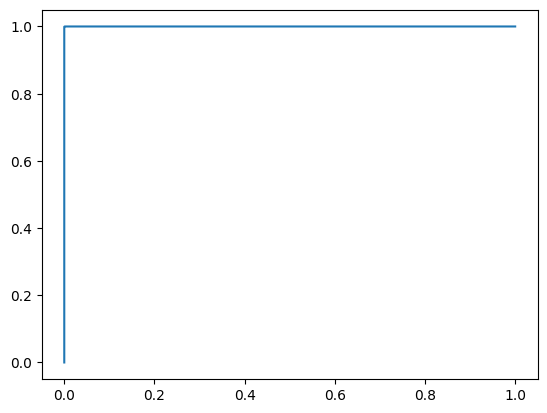

TrainingAUC:  0.9999996074706192


In [27]:
import matplotlib.pyplot as plt
trainsummary=lrModel.summary
roc=trainsummary.roc.toPandas()
plt.plot(roc['FPR'],roc['TPR'])
plt.show()
print("TrainingAUC: ",trainsummary.areaUnderROC)

In [28]:
predictions=lrModel.transform(test)
predictions.show()

+-----+--------------------+--------------------+--------------------+----------+
|label|            features|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+----------+
|  0.0|(43,[0,11,13,16,1...|[8.33637708380704...|[0.99976041844905...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[8.65875166384519...|[0.99982642924808...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[8.29101645865930...|[0.99974930341798...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[7.92655562500543...|[0.99963910250511...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[7.83844181127310...|[0.99960587246828...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[8.74114231783502...|[0.99984015439481...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[8.13428706829427...|[0.99970677793452...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[8.23415472285859...|[0.99973463919212...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[8.32111408558680...|[0.99975673456376...|       0.0|
|  0.0|(43,[0,11

In [29]:
from  pyspark.ml.evaluation import BinaryClassificationEvaluator
eval=BinaryClassificationEvaluator()
print("Test Area UNder Roc: ",eval.evaluate(predictions))

Test Area UNder Roc:  1.0


In [30]:
from pyspark.ml.classification import DecisionTreeClassifier
dr=DecisionTreeClassifier(featuresCol='features',labelCol="label",maxDepth=3)
drModel=dr.fit(train)
predictions_1=drModel.transform(test)
print("Test Area UNder Roc: ",eval.evaluate(predictions_1))

Test Area UNder Roc:  1.0


In [31]:
from pyspark.ml.classification import RandomForestClassifier
rf=RandomForestClassifier(featuresCol='features',labelCol="label")
rfModel=rf.fit(train)
predictions_rf=rfModel.transform(test)
predictions_rf.show(2)
print("Test Area UNder Roc: ",eval.evaluate(predictions_rf,{eval.metricName:"areaUnderROC"}))

+-----+--------------------+--------------------+--------------------+----------+
|label|            features|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+----------+
|  0.0|(43,[0,11,13,16,1...|[17.3992054166567...|[0.86996027083283...|       0.0|
|  0.0|(43,[0,11,13,16,1...|[17.4969284907763...|[0.87484642453881...|       0.0|
+-----+--------------------+--------------------+--------------------+----------+
only showing top 2 rows
Test Area UNder Roc:  1.0


In [32]:
from pyspark.ml.feature import MinMaxScaler

scaler = MinMaxScaler(
    inputCol="features",
    outputCol="scaledFeatures"
)

scalerModel = scaler.fit(train)

train = scalerModel.transform(train)
test = scalerModel.transform(test)
from pyspark.ml.classification import NaiveBayes
nb = NaiveBayes(
    featuresCol="scaledFeatures",
    labelCol="label"
)

nbModel = nb.fit(train)

predictions_nb = nbModel.transform(test)

predictions_nb.show(2)

print("Test Area UNder Roc: ",eval.evaluate(predictions_nb,{eval.metricName:"areaUnderROC"}))

+-----+--------------------+--------------------+--------------------+--------------------+----------+
|label|            features|      scaledFeatures|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+--------------------+----------+
|  0.0|(43,[0,11,13,16,1...|(43,[0,11,13,16,1...|[-33.861328898940...|[0.99940305072482...|       0.0|
|  0.0|(43,[0,11,13,16,1...|(43,[0,11,13,16,1...|[-35.367654501683...|[0.99944113883302...|       0.0|
+-----+--------------------+--------------------+--------------------+--------------------+----------+
only showing top 2 rows
Test Area UNder Roc:  0.9907313467133196


In [33]:
# Spark Setup
from pyspark.sql import SparkSession
spark=SparkSession.builder.appName("PySpark_Basics").master("local[*]").getOrCreate()

In [34]:

#You have Pandas it is possible to process large csv
#Daily receiving 15TB its not possible to load using Pandas
#Using Spark
sales_data=[
    (1,101,"Laptop",2,50000),
    (2,102,"Keyboard",1,1000),
    (3,103,"Mouse",3,5000),
]

In [35]:
sales=spark.createDataFrame(sales_data,["order_id","Customer_id","Product","Qty","Price"])

In [36]:
type(sales)

pyspark.sql.classic.dataframe.DataFrame

In [37]:
sales.show(2)

+--------+-----------+--------+---+-----+
|order_id|Customer_id| Product|Qty|Price|
+--------+-----------+--------+---+-----+
|       1|        101|  Laptop|  2|50000|
|       2|        102|Keyboard|  1| 1000|
+--------+-----------+--------+---+-----+
only showing top 2 rows


In [38]:
sales=sales.withColumn("total_amount",sales["Qty"]*sales["Price"])

In [39]:
sales.show(3)

+--------+-----------+--------+---+-----+------------+
|order_id|Customer_id| Product|Qty|Price|total_amount|
+--------+-----------+--------+---+-----+------------+
|       1|        101|  Laptop|  2|50000|      100000|
|       2|        102|Keyboard|  1| 1000|        1000|
|       3|        103|   Mouse|  3| 5000|       15000|
+--------+-----------+--------+---+-----+------------+



In [40]:
from pyspark.sql.functions import sum
result=sales.groupBy("Product").agg(sum("total_amount"))

In [41]:
result.show()

+--------+-----------------+
| Product|sum(total_amount)|
+--------+-----------------+
|  Laptop|           100000|
|   Mouse|            15000|
|Keyboard|             1000|
+--------+-----------------+

